In [23]:
# packages 
import numpy as np
import pandas as pd
import cvxpy as cp
import matplotlib.pyplot as plt
import networkx as nx 

from power_system_data import PowerSystemData


In [24]:
# import data of the network : topologies, capacities, RES, load and Generation scenario for 1 time step 
data = PowerSystemData()

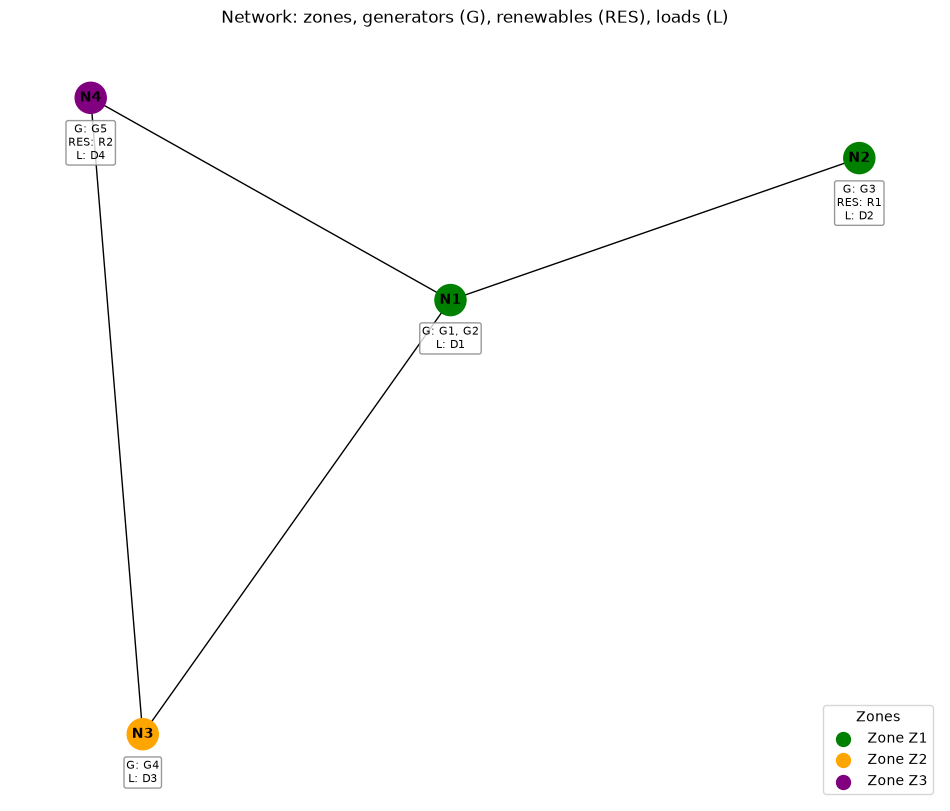

In [28]:
# Basic vizualization
G = nx.Graph()

for n in data.NODES:
    G.add_node(n,
               zone=data.node_zone[n],
               generators=data.generators_per_node.get(n, []),
               loads=data.loads_per_node.get(n, []),
               renewables=data.renewables_per_node.get(n, []))

for (n, m) in data.lines:
    G.add_edge(n, m, capacity=data.line_capacity_per_line[(n, m)])

# Draw the network with nodes coloured by zone
zone_colors = {'Z1': 'green', 'Z2': 'orange', 'Z3': 'purple'}

fig, ax = plt.subplots(figsize=(12, 10))
pos = nx.spring_layout(G, seed=42)   # fixed seed -> same layout every run

# One colour per node, in the same order as G.nodes
node_colors = [zone_colors[data.node_zone[n]] for n in G.nodes]

nx.draw(G, pos, ax=ax, with_labels=True, node_color=node_colors,
        node_size=500, font_size=10, font_weight='bold')

# Generators / renewables / loads written under each node
def asset_text(n):
    a = G.nodes[n]
    parts = []
    if a['generators']: parts.append("G: "   + ", ".join(map(str, a['generators'])))
    if a['renewables']: parts.append("RES: " + ", ".join(map(str, a['renewables'])))
    if a['loads']:      parts.append("L: "   + ", ".join(map(str, a['loads'])))
    return "\n".join(parts)

for n, (x, y) in pos.items():
    txt = asset_text(n)
    if txt:
        ax.annotate(txt, (x, y), xytext=(0, -18), textcoords='offset points',
                    ha='center', va='top', fontsize=8,
                    bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='grey', alpha=0.8))

# Zone legend
for zone, color in zone_colors.items():
    ax.scatter([], [], c=color, s=100, label=f"Zone {zone}")
ax.legend(title="Zones", loc="lower right")

ax.set_title("Network: zones, generators (G), renewables (RES), loads (L)")
plt.show()


In [29]:
for key, value in data.__dict__.items():
    print(f"{key}: {value}")


N_GENERATORS: 5
N_LOADS: 4
N_NODES: 4
N_ZONES: 3
N_SCENARIOS: 2
N_RES: 2
GENERATORS: ['G1', 'G2', 'G3', 'G4', 'G5']
LOADS: ['D1', 'D2', 'D3', 'D4']
NODES: ['N1', 'N2', 'N3', 'N4']
ZONES: ['Z1', 'Z2', 'Z3']
SCENARIOS: ['S1', 'S2']
RENEWABLES: ['R1', 'R2']
S_BASE_MVA: 100.0
V_BASE_KV: {'N1': 230.0, 'N2': 230.0, 'N3': 230.0, 'N4': 230.0}
time_step: 1
slack_bus: N1
nodes_per_zone: {'Z1': ['N1', 'N2'], 'Z2': ['N3'], 'Z3': ['N4']}
connections_per_node: {'N1': ['N2', 'N3', 'N4'], 'N2': ['N1'], 'N3': ['N1', 'N4'], 'N4': ['N1', 'N3']}
generators_per_node: {'N1': ['G1', 'G2'], 'N2': ['G3'], 'N3': ['G4'], 'N4': ['G5']}
loads_per_node: {'N1': ['D1'], 'N2': ['D2'], 'N3': ['D3'], 'N4': ['D4']}
renewables_per_node: {'N1': [], 'N2': ['R1'], 'N3': [], 'N4': ['R2']}
gen_linear_cost_coeff: {'G1': 9, 'G2': 20, 'G3': 10, 'G4': 11, 'G5': 12}
gen_down_deviation_cost_coeff: {'G1': 2, 'G2': 0, 'G3': 2, 'G4': 2, 'G5': 2}
gen_up_deviation_cost_coeff: {'G1': 2, 'G2': 0, 'G3': 2, 'G4': 2, 'G5': 2}
gen_max_capacity

In [39]:
def solve_base_case(data: PowerSystemData, load=None, res=None, solver=cp.GUROBI, verbose=False):
    """Day-ahead nodal dispatch (DC-OPF via PTDF) at a given load and renewable level.

    load: vector over data.LOADS;      defaults to data.expected_DA_load_vec.
    res:  vector over data.RENEWABLES; defaults to data.expected_DA_res_vec.
    """
    d = data.expected_DA_load_vec if load is None else np.asarray(load, float)
    r = data.expected_DA_res_vec if res is None else np.asarray(res, float)

    g = cp.Variable(len(data.GENERATORS), nonneg=True )                # generator output
    C = cp.Variable(len(data.RENEWABLES), nonneg=True)                # renewable curtailment
    I = cp.Variable(len(data.NODES))                     # nodal net injection
    f = cp.Variable(len(data.lines))                     # line flows

    nodal_balance = I == data.M_ng @ g + data.M_nr @ (r - C) - data.M_nd @ d   # G + r - C - d = P
    cons = [nodal_balance,
            f == data.PTDF @ I,
            cp.sum(I) == 0,
            g >= data.gen_min_vec, g <= data.gen_max_vec,
            C >= 0, C <= r, # C>0 redondant constraint 
            f <= data.line_cap_vec, f >= -data.line_cap_vec]
    prob = cp.Problem(cp.Minimize(data.gen_cost_vec @ g
                                  + data.res_curtailment_cost_vec @ C), cons)
    prob.solve(solver=solver, verbose=verbose)
    assert prob.status == cp.OPTIMAL, f"base case: {prob.status}"

    I_bc = I.value
    return dict(g=pd.Series(g.value, index=data.GENERATORS),
                C=pd.Series(C.value, index=data.RENEWABLES),
                P=pd.Series(I_bc, index=data.NODES),
                f=pd.Series(f.value, index=data.lines),
                NP=pd.Series(data.M_zn @ I_bc, index=data.ZONES),   # zonal net position
                LMP=pd.Series(nodal_balance.dual_value, index=data.NODES),  # nodal price
                cost=prob.value, 
                status = prob.status)

In [41]:
bc = solve_base_case(data, verbose=True)

(CVXPY) Oct 15 04:47:57 PM: Your problem has 15 variables, 31 constraints, and 0 parameters.
(CVXPY) Oct 15 04:47:57 PM: It is compliant with the following grammars: DCP, DQCP
(CVXPY) Oct 15 04:47:57 PM: DCP verification time: 0.0026 seconds.
(CVXPY) Oct 15 04:47:57 PM: Expression tree has 4 nodes.
(CVXPY) Oct 15 04:47:57 PM: (If you need to solve this problem multiple times, but with different data, consider using parameters.)
(CVXPY) Oct 15 04:47:57 PM: CVXPY will first compile your problem; then, it will invoke a numerical solver to obtain a solution.
(CVXPY) Oct 15 04:47:57 PM: Your problem is compiled with the CPP canonicalization backend.
(CVXPY) Oct 15 04:47:57 PM: Compiling problem (target solver=GUROBI).
(CVXPY) Oct 15 04:47:57 PM: Reduction chain: Dcp2Cone -> CvxAttr2Constr -> EliminateZeroSized -> ConeMatrixStuffing -> GUROBI
(CVXPY) Oct 15 04:47:57 PM: Applying reduction Dcp2Cone
(CVXPY) Oct 15 04:47:57 PM: Applying reduction CvxAttr2Constr
(CVXPY) Oct 15 04:47:57 PM: Apply

                                     CVXPY                                     
                                     v1.9.3                                    
-------------------------------------------------------------------------------
                                  Compilation                                  
-------------------------------------------------------------------------------
-------------------------------------------------------------------------------
                                Numerical solver                               
-------------------------------------------------------------------------------
Set parameter OutputFlag to value 1
Set parameter QCPDual to value 1
Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (mac64[arm] - Darwin 23.4.0 23E214)

CPU model: Apple M2
Thread count: 8 physical cores, 8 logical processors, using up to 8 threads

Non-default parameters:
QCPDual  1

Optimize a model with 31 rows, 15 columns and 48 nonzeros (Min)
Model fi

(CVXPY) Oct 15 04:47:57 PM: Problem status: optimal
(CVXPY) Oct 15 04:47:57 PM: Optimal value: 2.526e+02
(CVXPY) Oct 15 04:47:57 PM: Compilation took 1.749e-02 seconds
(CVXPY) Oct 15 04:47:57 PM: Solver (including time spent in interface) took 6.019e-03 seconds


-------------------------------------------------------------------------------
                                    Summary                                    
-------------------------------------------------------------------------------


In [42]:
for k, v in bc.items():
    print(f"{k}:\n{v}\n")

g:
G1    20.0
G2     0.0
G3     2.2
G4     4.6
G5     0.0
dtype: float64

C:
R1    0.0
R2    0.0
dtype: float64

P:
N1    14.2
N2    10.0
N3   -12.2
N4   -12.0
dtype: float64

f:
(N1, N2)   -10.000000
(N1, N3)    12.133333
(N1, N4)    12.066667
(N3, N4)    -0.066667
dtype: float64

NP:
Z1    24.2
Z2   -12.2
Z3   -12.0
dtype: float64

LMP:
N1    11.0
N2    10.0
N3    11.0
N4    11.0
dtype: float64

cost:
252.59999999999997

status:
optimal

